In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [3]:
os.makedirs("phase2_charts", exist_ok=True)

In [4]:
# load the cleaned datasets

subscribers = pd.read_csv('subscribers_cleaned.csv')
titles = pd.read_csv('titles_cleaned.csv')
watchlist = pd.read_csv('watchlist_cleaned.csv')
watch_history = pd.read_csv('watch_history_cleaned.csv')
rating = pd.read_csv('ratings_cleaned.csv')
reviews = pd.read_csv('reviews_cleaned.csv')

In [5]:
watch_history["watch_date"] = pd.to_datetime(
    watch_history["watch_date"],
    errors="coerce"
)

subscribers["signup_date"] = pd.to_datetime(
    subscribers["signup_date"],
    errors="coerce"
)

subscribers["churn_date"] = pd.to_datetime(
    subscribers["churn_date"],
    errors="coerce"
)

In [6]:
print(watch_history.shape)
print(titles.shape)
print(subscribers.shape)
print(reviews.shape)

print(watch_history.dtypes)

(650000, 10)
(9000, 21)
(15000, 14)
(110000, 7)
watch_id                         int64
subscriber_id                   object
title_id                        object
watch_date              datetime64[ns]
device                          object
region                          object
content_duration_min             int64
watch_duration_min             float64
completion_pct                 float64
completed                         bool
dtype: object


In [7]:
# monthly viewing volume
monthly_sessions = (
    watch_history
    .set_index("watch_date")
    .resample("ME")["watch_id"]
    .count()
)

monthly_sessions.head()

watch_date
2017-03-31    1
2017-04-30    1
2017-05-31    1
2017-06-30    0
2017-07-31    1
Freq: ME, Name: watch_id, dtype: int64

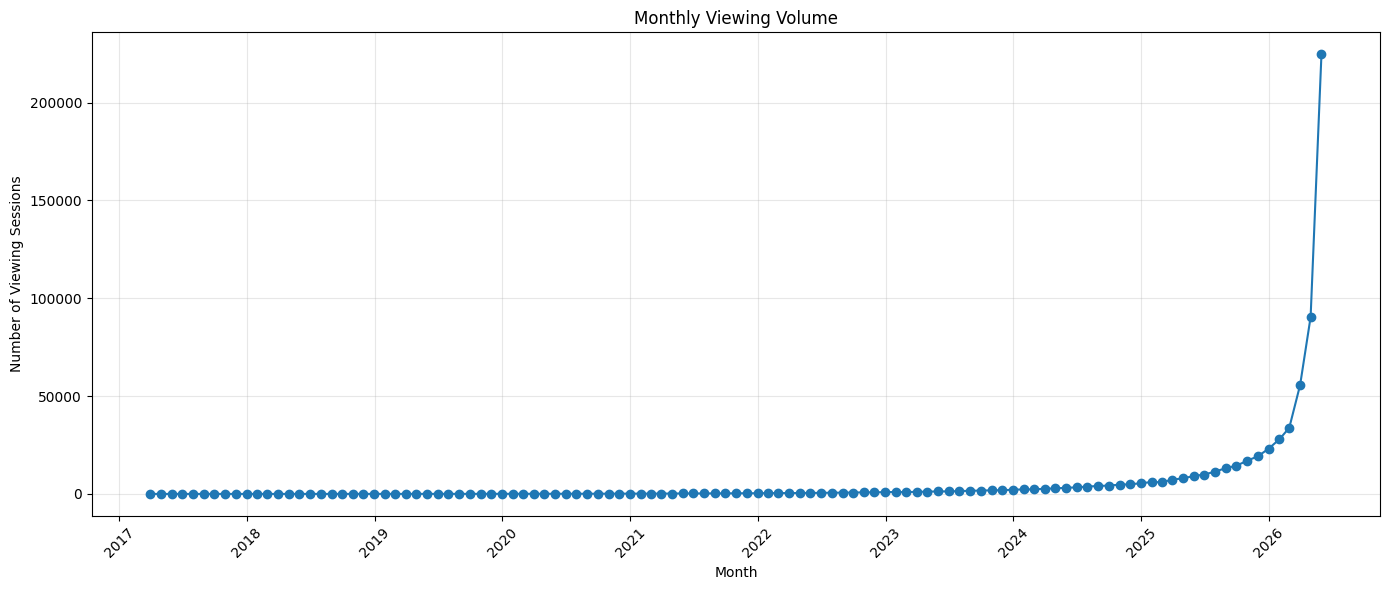

In [8]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sessions.index,
    monthly_sessions.values,
    marker="o"
)

plt.title("Monthly Viewing Volume")
plt.xlabel("Month")
plt.ylabel("Number of Viewing Sessions")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "phase2_charts/monthly_viewing_volume.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
monthly_sessions.sort_values(ascending=False).head(5)

watch_date
2026-05-31    224696
2026-04-30     90383
2026-03-31     55665
2026-02-28     33795
2026-01-31     27970
Name: watch_id, dtype: int64

Monthly Watch Hours Trend


In [10]:
watch_history["watch_hours"] = (
    watch_history["watch_duration_min"] / 60
)

In [11]:
monthly_watch_hours = (
    watch_history
    .set_index("watch_date")
    .resample("ME")["watch_hours"]
    .sum()
)

monthly_watch_hours.head()

watch_date
2017-03-31     4.773333
2017-04-30     4.400000
2017-05-31    14.416667
2017-06-30     0.000000
2017-07-31     1.413333
Freq: ME, Name: watch_hours, dtype: float64

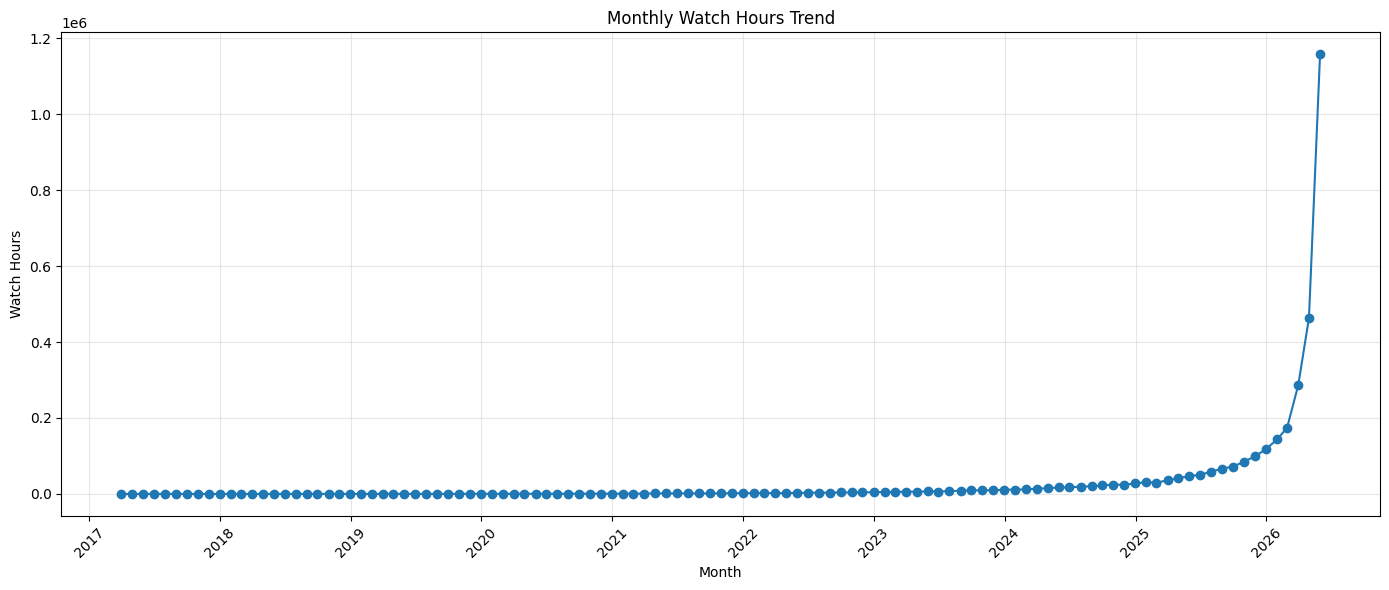

In [12]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_watch_hours.index,
    monthly_watch_hours.values,
    marker="o"
)

plt.title("Monthly Watch Hours Trend")
plt.xlabel("Month")
plt.ylabel("Watch Hours")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "phase2_charts/monthly_watch_hours.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
monthly_watch_hours_df = monthly_watch_hours.reset_index()

monthly_watch_hours_df["year"] = (
    monthly_watch_hours_df["watch_date"].dt.year
)

monthly_watch_hours_df["month"] = (
    monthly_watch_hours_df["watch_date"].dt.month
)

In [14]:
year_month_watch = monthly_watch_hours_df.pivot(
    index="month",
    columns="year",
    values="watch_hours"
)

year_month_watch

year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
month,,,,,,,,,,
1,NaN,66.530000,118.450000,257.963333,904.846667,2136.568333,5232.415000,11494.471667,31264.428333,1.435220e+05
2,NaN,46.891667,50.088333,306.293333,741.286667,2145.071667,4557.081667,11742.558333,29351.955000,1.745655e+05
3,4.773333,7.286667,132.055000,383.570000,952.956667,2198.875000,6125.530000,14086.928333,36105.896667,2.860884e+05
4,4.400000,16.250000,101.231667,303.401667,1242.140000,2134.000000,5263.458333,14666.145000,41127.996667,4.633373e+05
5,14.416667,39.560000,160.305000,407.563333,1223.748333,2703.285000,6869.423333,17028.823333,46932.975000,1.157786e+06
6,0.000000,26.671667,72.126667,473.070000,1104.550000,2989.763333,6357.055000,17264.141667,50131.456667,NaN
7,1.413333,56.056667,52.911667,362.165000,1359.903333,3360.791667,7377.758333,19355.131667,58682.746667,NaN
8,0.000000,38.948333,142.576667,472.580000,1323.488333,3407.005000,8489.328333,19915.335000,66709.368333,NaN
9,2.610000,38.015000,96.310000,553.120000,1220.986667,3845.931667,9068.906667,22454.820000,71766.830000,NaN


Genre-wise Watch-hours Share

In [15]:
watch_genre = watch_history.merge(
    titles[["title_id", "primary_genre"]],
    on="title_id",
    how="left"
)

In [16]:
genre_watch_hours = (
    watch_genre
    .groupby("primary_genre")["watch_hours"]
    .sum()
    .sort_values(ascending=False)
)

genre_watch_hours

primary_genre
Drama            501884.466667
Comedy           423149.053333
Action           393171.916667
Thriller         307024.663333
Documentary      291216.898333
Crime            237435.838333
Romance          214332.301667
Animation        180093.938333
Sci-Fi           154332.208333
Horror           138033.605000
Fantasy          127838.850000
Reality          103954.906667
Kids & Family    103118.066667
Mystery           82552.373333
Musical           39023.391667
Stand-Up          36305.255000
Name: watch_hours, dtype: float64

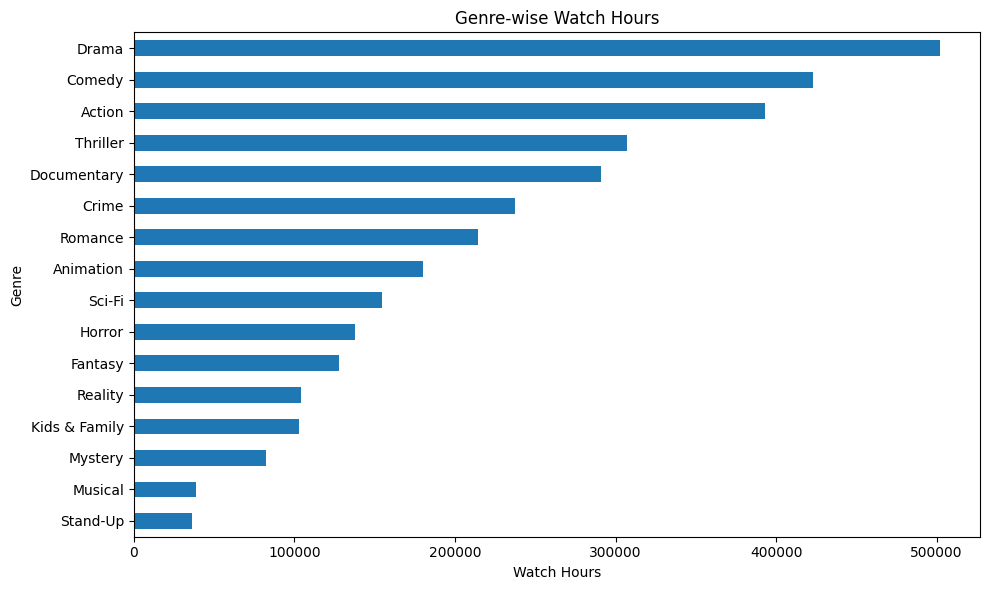

In [17]:
plt.figure(figsize=(10, 6))

genre_watch_hours.sort_values().plot(
    kind="barh"
)

plt.title("Genre-wise Watch Hours")
plt.xlabel("Watch Hours")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig(
    "phase2_charts/genre_watch_hours.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [18]:
genre_watch_hours.head(1)

primary_genre
Drama    501884.466667
Name: watch_hours, dtype: float64

Content Type Split

In [19]:
watch_content = watch_history.merge(
    titles[["title_id", "type"]],
    on="title_id",
    how="left"
)

In [20]:
content_type_hours = (
    watch_content
    .groupby("type")["watch_hours"]
    .sum()
)

content_type_hours

type
Movie      4.508588e+05
TV Show    2.882609e+06
Name: watch_hours, dtype: float64

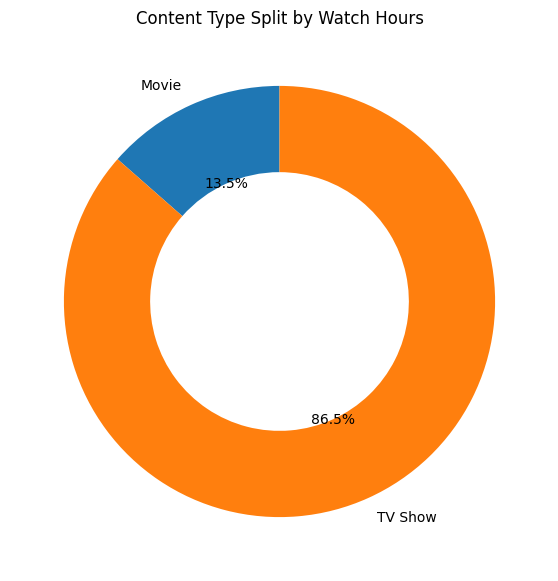

In [21]:
plt.figure(figsize=(7, 7))

plt.pie(
    content_type_hours.values,
    labels=content_type_hours.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)

plt.title("Content Type Split by Watch Hours")

plt.savefig(
    "phase2_charts/content_type_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Top 10 Countries by Watch Hours

In [22]:
watch_history.columns

Index(['watch_id', 'subscriber_id', 'title_id', 'watch_date', 'device',
       'region', 'content_duration_min', 'watch_duration_min',
       'completion_pct', 'completed', 'watch_hours'],
      dtype='object')

In [23]:
country_watch_hours = (
    watch_history
    .groupby("region")["watch_hours"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_watch_hours

region
North America     1.013484e+06
Europe            8.211636e+05
East Asia         4.112069e+05
Latin America     3.976540e+05
South Asia        3.809177e+05
Middle East       1.116150e+05
Southeast Asia    7.681218e+04
Africa            6.097477e+04
Oceania           5.963973e+04
Name: watch_hours, dtype: float64

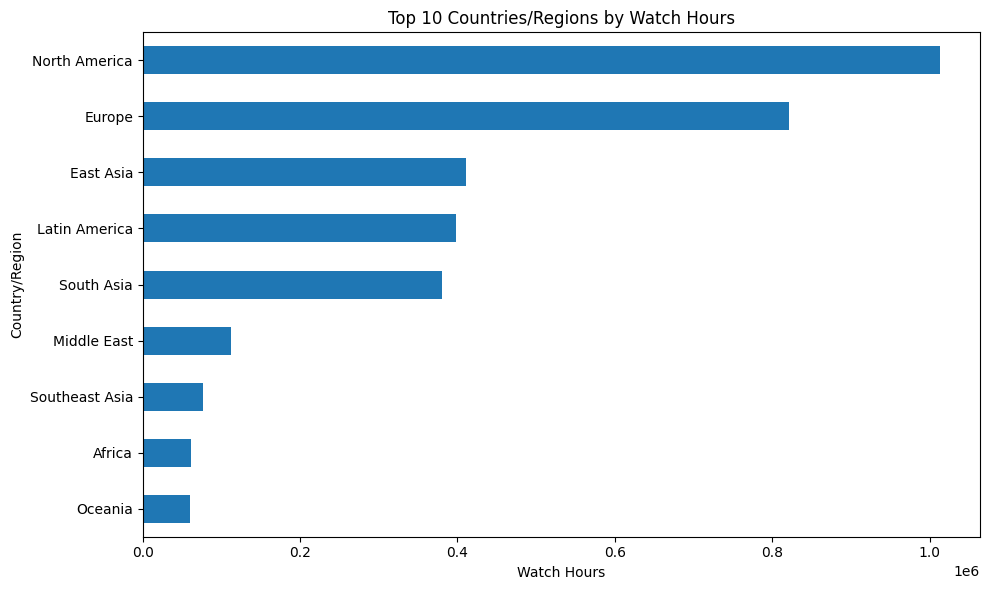

In [24]:
plt.figure(figsize=(10, 6))

country_watch_hours.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Countries/Regions by Watch Hours")
plt.xlabel("Watch Hours")
plt.ylabel("Country/Region")
plt.tight_layout()

plt.savefig(
    "phase2_charts/top_10_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Subscriber Plan Distribution

In [25]:
subscribers.columns

Index(['subscriber_id', 'signup_date', 'country', 'region', 'age', 'gender',
       'plan_type', 'monthly_price_usd', 'household_size', 'primary_device',
       'payment_method', 'tenure_months', 'is_active', 'churn_date'],
      dtype='object')

In [27]:
plan_counts = subscribers["plan_type"].value_counts()

plan_counts

plan_type
Standard          6100
Basic with Ads    4458
Premium           4442
Name: count, dtype: int64

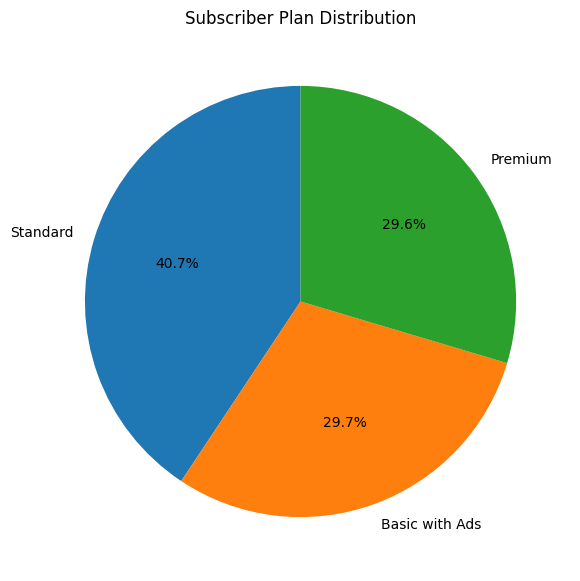

In [28]:
plt.figure(figsize=(7, 7))

plt.pie(
    plan_counts.values,
    labels=plan_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Subscriber Plan Distribution")

plt.savefig(
    "phase2_charts/subscriber_plan.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Device Usage

In [29]:
device_counts = (
    watch_history["device"]
    .value_counts()
)

device_counts

device
Smart TV           221446
Mobile             175605
Laptop              96408
Tablet              65276
Game Console        52322
Streaming Stick     38943
Name: count, dtype: int64

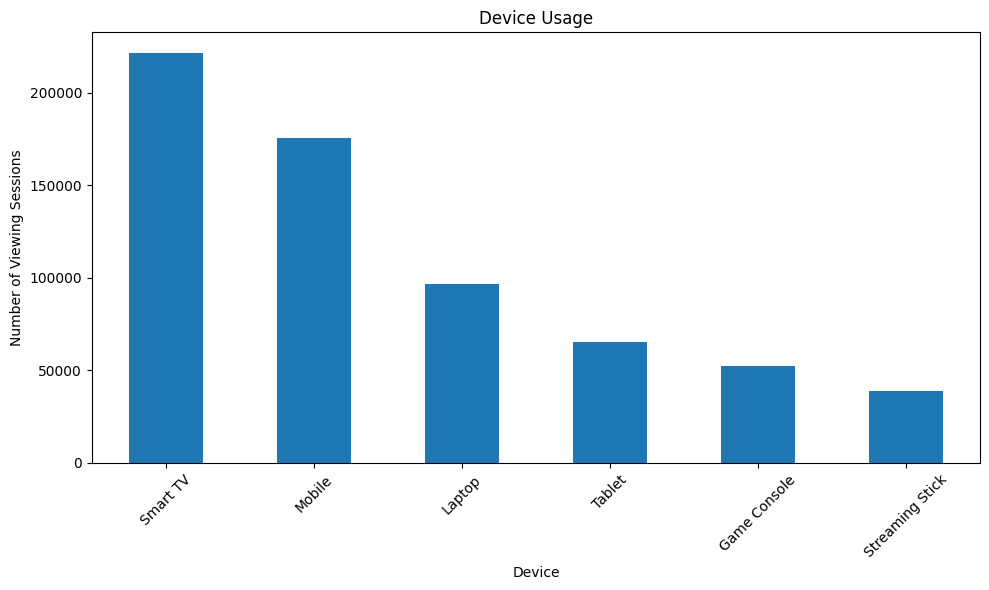

In [30]:
plt.figure(figsize=(10, 6))

device_counts.plot(
    kind="bar"
)

plt.title("Device Usage")
plt.xlabel("Device")
plt.ylabel("Number of Viewing Sessions")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "phase2_charts/device_usage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Age Distribution of Subscribers

In [31]:
subscribers.columns

Index(['subscriber_id', 'signup_date', 'country', 'region', 'age', 'gender',
       'plan_type', 'monthly_price_usd', 'household_size', 'primary_device',
       'payment_method', 'tenure_months', 'is_active', 'churn_date'],
      dtype='object')

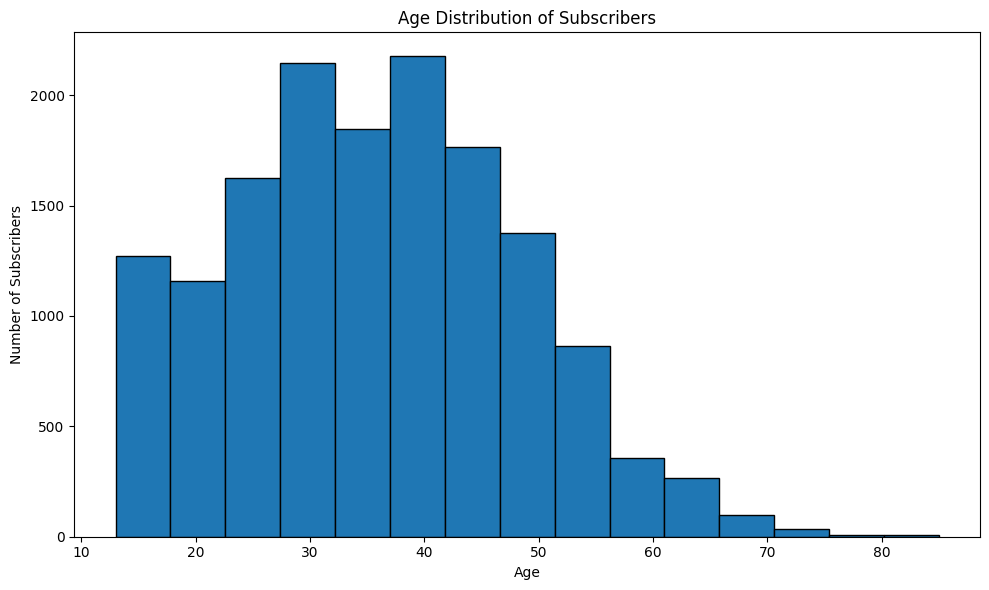

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(
    subscribers["age"].dropna(),
    bins=15,
    edgecolor="black"
)

plt.title("Age Distribution of Subscribers")
plt.xlabel("Age")
plt.ylabel("Number of Subscribers")
plt.tight_layout()

plt.savefig(
    "phase2_charts/age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Completion Rate by Genre

In [33]:
watch_completion = watch_history.merge(
    titles[["title_id", "primary_genre"]],
    on="title_id",
    how="left"
)

In [34]:
completion_by_genre = (
    watch_completion
    .groupby("primary_genre")["completion_pct"]
    .mean()
    .sort_values(ascending=False)
)

completion_by_genre

primary_genre
Musical          66.834788
Animation        66.383549
Stand-Up         66.319730
Fantasy          65.968073
Sci-Fi           65.793368
Mystery          65.558980
Crime            65.461294
Comedy           65.316334
Kids & Family    65.309259
Thriller         65.307925
Horror           65.259533
Documentary      65.127758
Drama            65.104168
Romance          65.004707
Action           64.812501
Reality          64.700084
Name: completion_pct, dtype: float64

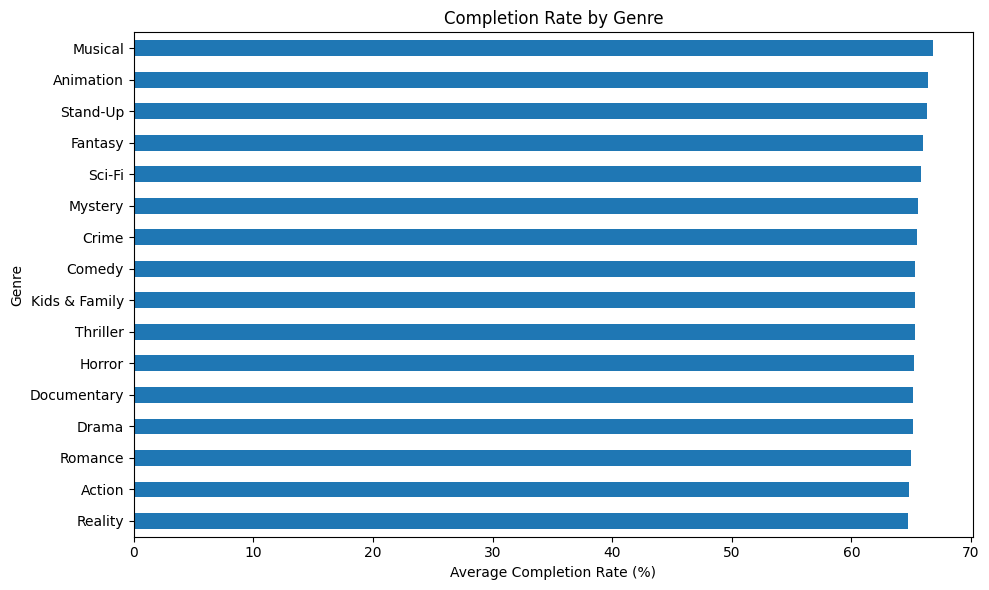

In [35]:
plt.figure(figsize=(10, 6))

completion_by_genre.sort_values().plot(
    kind="barh"
)

plt.title("Completion Rate by Genre")
plt.xlabel("Average Completion Rate (%)")
plt.ylabel("Genre")
plt.tight_layout()

plt.savefig(
    "phase2_charts/completion_by_genre.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Review Sentiment Breakdown

In [36]:
reviews.columns

Index(['review_id', 'subscriber_id', 'title_id', 'review_text', 'sentiment',
       'helpful_votes', 'review_date'],
      dtype='object')

In [37]:
reviews["sentiment"].value_counts()

sentiment
Positive    75007
Neutral     22759
Negative    12234
Name: count, dtype: int64

In [38]:
sentiment_counts = reviews["sentiment"].value_counts()

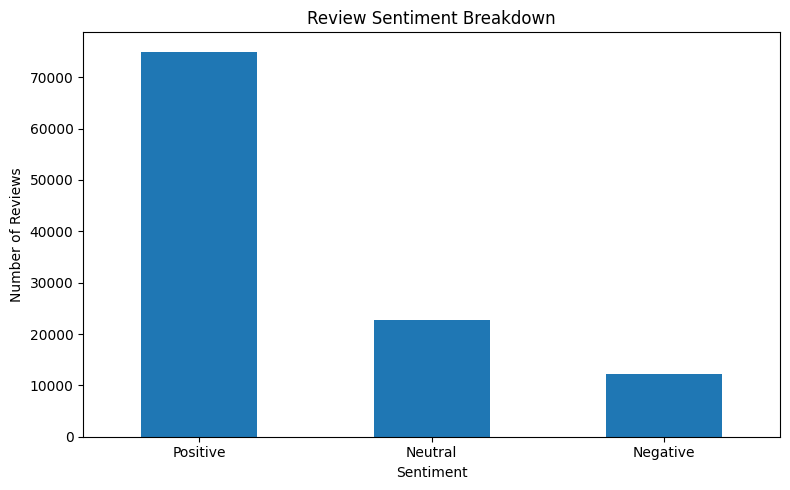

In [39]:
plt.figure(figsize=(8, 5))

sentiment_counts.plot(
    kind="bar"
)

plt.title("Review Sentiment Breakdown")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "phase2_charts/review_sentiment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()